# Clase práctica: reducción de dimensionalidad (PCA y t-SNE)

**Objetivos**

1. Entender por qué muchas variables complican el análisis (redundancia, visualización, distancias).
2. Aplicar **PCA**: componentes, varianza explicada, cuántos componentes conservar e interpretación de *loadings*.
3. Aplicar **t-SNE** para visualización no lineal y conocer sus limitaciones.
4. Comprobar cómo la reducción afecta un análisis posterior (clustering).

> Esta clase antecede a [clase_practica_kmeans_jerarquico.ipynb](clase_practica_kmeans_jerarquico.ipynb), donde PCA se usa para visualizar clusters.

**Con tus propios datos:** cambia la celda de carga (sección 1) y define `X` (solo columnas numéricas) y, opcionalmente, `y` (etiqueta, solo para colorear).

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style='whitegrid')
SEED = 42

## 1. Datos

Dataset *Wine*: 178 vinos y 13 mediciones químicas. No podemos graficar 13 dimensiones, pero sí intuir que varias variables están correlacionadas (aportan información redundante).

In [17]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target.map(dict(enumerate(wine.target_names)))   # solo para colorear
print(X.shape)
X.head()

(178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


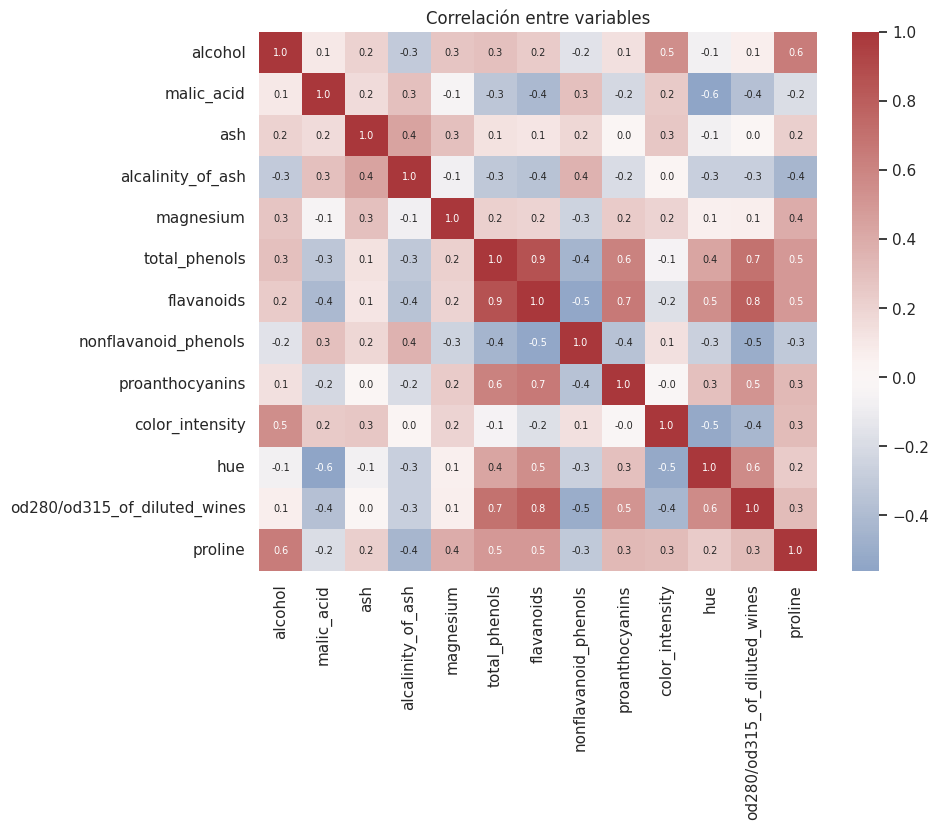

In [18]:
plt.figure(figsize=(9, 7))
sns.heatmap(X.corr(), cmap='vlag', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlación entre variables')
plt.show()

**Pregunta 1.** ¿Qué pares de variables están muy correlacionados? ¿Qué implica para la cantidad de información "realmente distinta" que hay en los datos?

## 2. Escalamiento previo

PCA busca direcciones de máxima **varianza**; una variable con escala grande (p. ej. `proline`) dominaría. Comparemos con y sin escalar.

In [19]:
Xs = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns)

pca_raw = PCA().fit(X)
pca_std = PCA().fit(Xs)
print('PC1 sin escalar :', f'{pca_raw.explained_variance_ratio_[0]:.1%}')
print('PC1 escalado    :', f'{pca_std.explained_variance_ratio_[0]:.1%}')

carga = pd.Series(pca_raw.components_[0], index=X.columns).abs().sort_values(ascending=False)
print('\nVariables con mayor peso en PC1 sin escalar:')
print(carga.head(3).round(3))

PC1 sin escalar : 99.8%
PC1 escalado    : 36.2%

Variables con mayor peso en PC1 sin escalar:
proline              1.000
magnesium            0.018
alcalinity_of_ash    0.005
dtype: float64


Sin escalar, PC1 es prácticamente la variable de mayor escala. **Siempre se estandariza antes de PCA** cuando las unidades difieren.

## 3. PCA paso a paso

Idea: encontrar nuevos ejes (combinaciones lineales de las variables) **ortogonales** y ordenados por la varianza que capturan. Equivale a rotar los datos y quedarnos con los primeros ejes.

Intuición en 2D con dos variables: dibujamos los ejes principales.

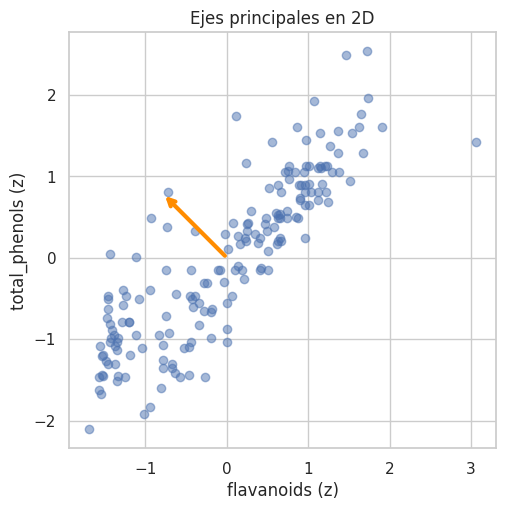

Varianza explicada: [0.932 0.068]


In [20]:
dos = Xs[['flavanoids', 'total_phenols']]
p2 = PCA(n_components=2).fit(dos)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(dos.iloc[:, 0], dos.iloc[:, 1], alpha=0.5)
for comp, var, c in zip(p2.components_, p2.explained_variance_, ['crimson', 'darkorange']):
    ax.annotate('', xy=comp * 3 * np.sqrt(var), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=c, lw=3))
ax.set(xlabel='flavanoids (z)', ylabel='total_phenols (z)', title='Ejes principales en 2D')
ax.set_aspect('equal')
plt.show()
print('Varianza explicada:', p2.explained_variance_ratio_.round(3))

### 3.1 PCA completo y varianza explicada

¿Cuántos componentes conservar? Criterios habituales: **varianza acumulada** (p. ej. ≥ 80-90 %), **gráfico de sedimentación** (*scree*, buscar el codo) y **regla de Kaiser** (autovalor > 1 con datos estandarizados).

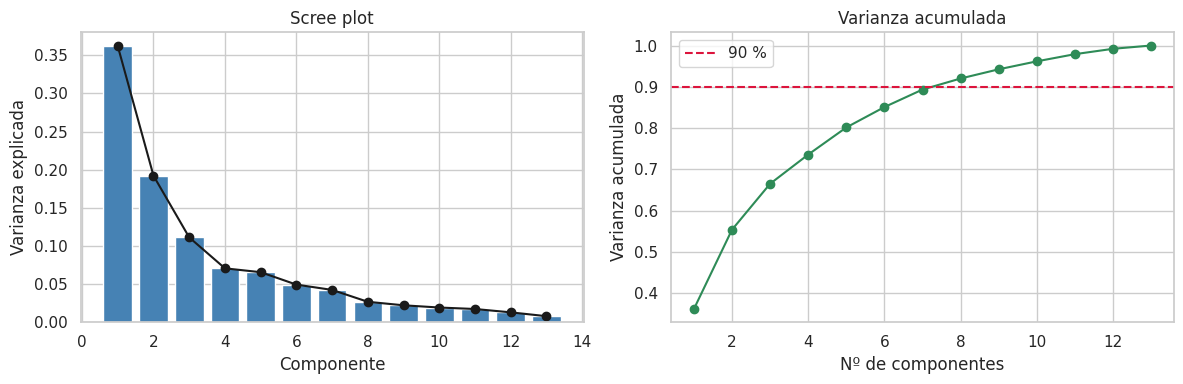

Componentes para 80 %: 5
Componentes para 90 %: 8
Kaiser (autovalor > 1): 3


In [21]:
pca = PCA(random_state=SEED).fit(Xs)
var = pca.explained_variance_ratio_
acum = var.cumsum()
n = np.arange(1, len(var) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(n, var, color='steelblue')
axes[0].plot(n, var, 'o-', color='k')
axes[0].set(xlabel='Componente', ylabel='Varianza explicada', title='Scree plot')

axes[1].plot(n, acum, 'o-', color='seagreen')
axes[1].axhline(0.9, color='crimson', ls='--', label='90 %')
axes[1].set(xlabel='Nº de componentes', ylabel='Varianza acumulada', title='Varianza acumulada')
axes[1].legend()
plt.tight_layout()
plt.show()

print('Componentes para 80 %:', int(np.argmax(acum >= 0.80)) + 1)
print('Componentes para 90 %:', int(np.argmax(acum >= 0.90)) + 1)
print('Kaiser (autovalor > 1):', int((pca.explained_variance_ > 1).sum()))

**Pregunta 2.** ¿Cuántos componentes conservarías y por qué? ¿Los tres criterios coinciden?

### 3.2 Proyección en 2D

In [ ]:
P = PCA(n_components=2, random_state=SEED).fit_transform(Xs)

plt.figure(figsize=(7, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=y, palette='tab10', s=55)
plt.xlabel(f'PC1 ({var[0]:.1%})'); plt.ylabel(f'PC2 ({var[1]:.1%})')
plt.title('Wine en los dos primeros componentes')
plt.show()

### 3.3 Interpretación: *loadings*

Cada componente es una combinación lineal de las variables originales. Los *loadings* indican cuánto pesa cada variable en cada componente.

In [ ]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=['PC1', 'PC2', 'PC3'])

plt.figure(figsize=(5.5, 6))
sns.heatmap(loadings, cmap='vlag', center=0, annot=True, fmt='.2f')
plt.title('Loadings')
plt.show()

print('Variables que más definen PC1:')
print(loadings['PC1'].abs().sort_values(ascending=False).head(4).round(2))

### 3.4 Biplot: observaciones y variables a la vez

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=y, palette='tab10', s=40, alpha=0.6, ax=ax)
esc = 4
for v in X.columns:
    ax.arrow(0, 0, loadings.loc[v, 'PC1'] * esc, loadings.loc[v, 'PC2'] * esc,
             color='k', alpha=0.6, head_width=0.08)
    ax.text(loadings.loc[v, 'PC1'] * esc * 1.1, loadings.loc[v, 'PC2'] * esc * 1.1, v, fontsize=8)
ax.set(xlabel=f'PC1 ({var[0]:.1%})', ylabel=f'PC2 ({var[1]:.1%})', title='Biplot')
plt.show()

**Pregunta 3.** ¿Qué variables apuntan en la misma dirección? ¿Qué tipo de vino queda asociado a valores altos de PC1?

### 3.5 Reconstrucción y error

Al descartar componentes perdemos información. Medimos el error de reconstrucción según los componentes retenidos.

In [ ]:
errores = []
for k in range(1, 14):
    p = PCA(n_components=k).fit(Xs)
    rec = p.inverse_transform(p.transform(Xs))
    errores.append(((Xs.values - rec) ** 2).mean())

plt.figure(figsize=(6, 3.8))
plt.plot(range(1, 14), errores, 'o-')
plt.xlabel('Componentes retenidos'); plt.ylabel('Error cuadrático medio')
plt.title('Error de reconstrucción')
plt.show()

## 4. t-SNE: visualización no lineal

PCA solo capta estructura **lineal**. t-SNE conserva vecindades locales y suele separar mejor los grupos en 2D, pero:

- las **distancias entre grupos** y los **tamaños** no son interpretables;
- depende de `perplexity` y de la semilla;
- no tiene `transform` para datos nuevos; **sirve para visualizar, no para modelar**.

In [ ]:
perplexities = [5, 30, 60]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, perp in zip(axes, perplexities):
    T = TSNE(n_components=2, perplexity=perp, init='pca', random_state=SEED).fit_transform(Xs)
    sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=y, palette='tab10', s=40, ax=ax, legend=(perp == 60))
    ax.set_title(f't-SNE, perplexity = {perp}')
plt.tight_layout()
plt.show()

**Pregunta 4.** ¿Cómo cambia la figura con la perplexity? ¿Qué conclusiones **no** deberías sacar de un t-SNE?

### PCA vs t-SNE

In [ ]:
T = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(Xs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, Z, tit in zip(axes, [P, T], ['PCA', 't-SNE']):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, palette='tab10', s=45, ax=ax)
    ax.set_title(tit)
plt.tight_layout()
plt.show()

## 5. ¿Qué pasa con el clustering al reducir dimensiones?

Agrupamos con K-means (k = 3) usando: todas las variables, los primeros *m* componentes principales y solo 2 componentes. Comparamos con las etiquetas reales (ARI) y la silueta.

In [ ]:
filas = []
for nombre, datos in [('13 variables', Xs.values)] + \
        [(f'PCA {m} comp.', PCA(n_components=m, random_state=SEED).fit_transform(Xs)) for m in (2, 3, 5, 8)]:
    lab = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(datos)
    filas.append({'Entrada': nombre,
                  'ARI vs real': adjusted_rand_score(wine.target, lab),
                  'Silueta': silhouette_score(datos, lab)})
pd.DataFrame(filas).round(3)

**Pregunta 5.** ¿Mejora o empeora el clustering al reducir? ¿Por qué la silueta no es comparable directamente entre espacios de distinta dimensión?

> Aviso: **no** se hace clustering sobre un t-SNE para "descubrir" grupos reales; las distancias allí están distorsionadas.

## 6. Ejercicios

1. Aplica PCA a `ejercicios/data/peptides.csv` (quita `Class`, imputa/elimina faltantes y estandariza). ¿Cuántos componentes explican el 90 %? Hay muchas más variables que muestras, ¿qué observas?
2. Repite la sección 5 con ese dataset y compara agrupar con todas las variables vs. con los primeros componentes.
3. Calcula el PCA sin estandarizar y explica por qué cambian los *loadings*.
4. Prueba `PCA(n_components=0.9)`; ¿qué hace ese parámetro?
5. Escribe un párrafo interpretando PC1 y PC2 en el contexto de los datos.

## Cierre

- PCA: lineal, determinista, interpretable (loadings), útil para visualizar, quitar redundancia y como preprocesamiento.
- t-SNE: no lineal, solo para visualizar; cuidado con su interpretación.
- Estandariza antes de reducir; decide el número de componentes con varianza acumulada, scree y el objetivo del análisis.
- Siguiente clase: clustering con K-means y jerárquico.